# Customer Churn Analysis

## Project Overview

This project analyses customer churn in a telecommunications company using Python.

### Objectives
- Understand customer churn patterns.
- Identify high-risk customer segments.
- Explore factors associated with customer churn.
- Develop business recommendations to improve customer retention.

**Tools:** Python, Pandas, Matplotlib, Seaborn

# Customer Churn Analysis & Retention Insights

## 1. Project Setup and Dataset Loading

This project analyses customer churn using the IBM Telco Customer Churn dataset.

The analysis uses Python, Pandas, Matplotlib, and Seaborn to explore customer behaviour, identify churn patterns, and create visualisations that support business decisions.

In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("../data/Telco-Customer-Churn-Cleaned.csv")

# Display dataset dimensions and preview
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Dashboard Visual Theme

Set a consistent visual style for all charts using Seaborn and Matplotlib. This includes the background, text colours, grid style, and image resolution.

In [2]:
# Dashboard visual theme

sns.set_theme(
    style="whitegrid",
    rc={
        "figure.facecolor": "#DCE5ED",
        "axes.facecolor": "#DCE5ED",
        "axes.edgecolor": "#D8E1E8",
        "axes.labelcolor": "#183B56",
        "xtick.color": "#183B56",
        "ytick.color": "#183B56",
        "font.family": "DejaVu Sans"
    }
)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300


## 3. Customer Churn Distribution

Visualise the proportion of customers who stayed with the company and those who churned. A donut chart displays both customer counts and percentages to show the overall churn situation.

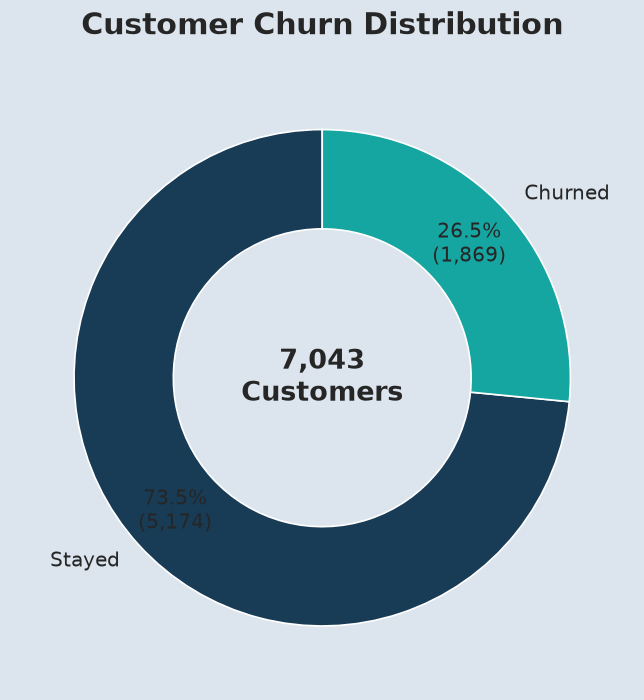

In [3]:
# Calculate customer counts by churn status
churn_counts = df["Churn"].value_counts()

labels = ["Stayed", "Churned"]
colors = ["#183B56", "#16A6A1"]

# Create the donut chart
fig, ax = plt.subplots(figsize=(8, 6))

ax.pie(
    churn_counts,
    labels=labels,
    colors=colors,
    autopct=lambda pct: f"{pct:.1f}%\n({int(round(pct * sum(churn_counts) / 100)):,})",
    startangle=90,
    pctdistance=0.8,
    wedgeprops={"width": 0.4, "edgecolor": "white"},
    textprops={"fontsize": 12}
)

# Display total customer count in the centre
ax.text(
    0, 0, f"{len(df):,}\nCustomers",
    ha="center", va="center",
    fontsize=16, fontweight="bold"
)

ax.set_title(
    "Customer Churn Distribution",
    fontsize=18, fontweight="bold", pad=20
)

plt.tight_layout()

# Export the chart at 300 DPI
plt.savefig(
    "../Visualizations/01_customer_churn_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=plt.gcf().get_facecolor()
)

# Display the chart
plt.show()

## 4. Churn Rate by Contract Type

Compare customer churn rates across month-to-month, one-year, and two-year contracts. This visualisation highlights which contract types have higher customer attrition, helping identify potential customer retention risks.

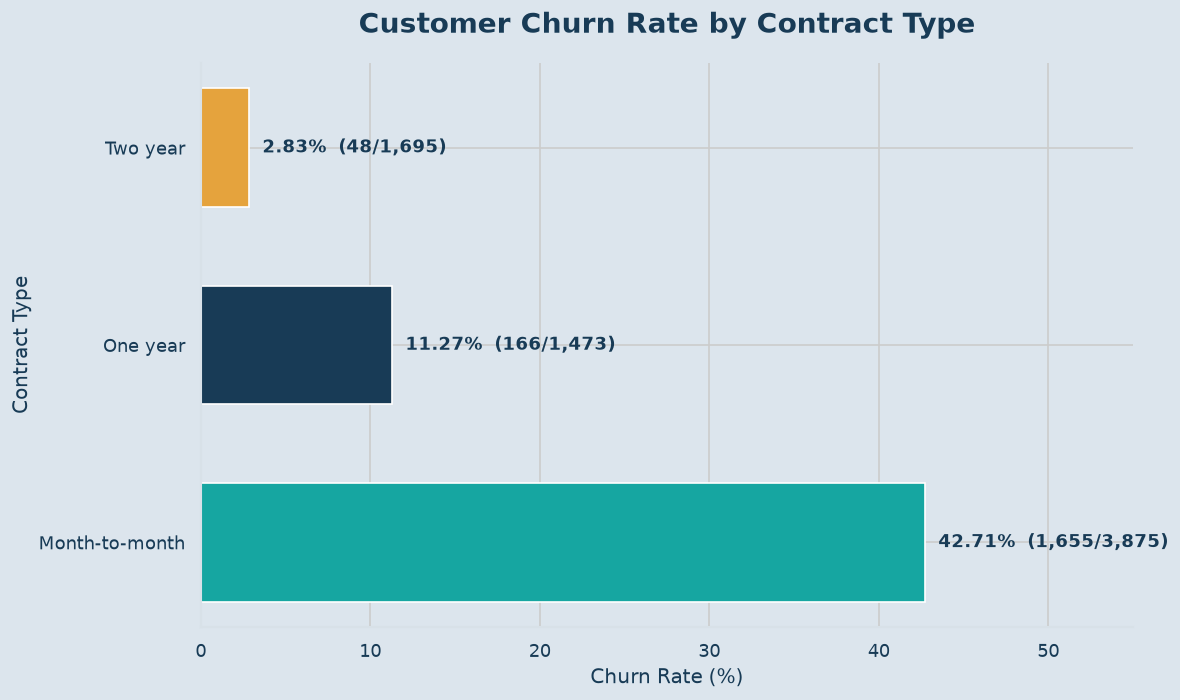

In [4]:
# Calculate churn rate by contract type
contract_churn = (
    pd.crosstab(
        df["Contract"],
        df["Churn"],
        normalize="index"
    )["Yes"] * 100
)

contract_churn = contract_churn.sort_values(ascending=False)

# Calculate total and churned customers for each contract type
contract_counts = df["Contract"].value_counts().reindex(contract_churn.index)

churn_counts = (
    df[df["Churn"] == "Yes"]["Contract"]
    .value_counts()
    .reindex(contract_churn.index)
)

# Create the horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#16A6A1", "#183B56", "#E5A33D"]

bars = ax.barh(
    contract_churn.index,
    contract_churn.values,
    color=colors,
    height=0.6
)

# Display churn rates and customer counts
for bar, rate, count, total in zip(
    bars,
    contract_churn.values,
    churn_counts,
    contract_counts
):
    ax.text(
        bar.get_width() + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}%  ({count:,}/{total:,})",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#183B56"
    )

ax.set_title(
    "Customer Churn Rate by Contract Type",
    fontsize=17,
    fontweight="bold",
    color="#183B56",
    pad=18
)

ax.set_xlabel("Churn Rate (%)", fontsize=12)
ax.set_ylabel("Contract Type", fontsize=12)
ax.set_xlim(0, 55)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Export the chart at 300 DPI
plt.savefig(
    "../Visualizations/02_churn_by_contract.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=plt.gcf().get_facecolor()
)

# Display the chart
plt.show()

## 5. Average Monthly Charges by Customer Status

Compare the average monthly charges of customers who stayed with the company and those who churned. This visualisation helps identify differences in monthly spending between the two groups.

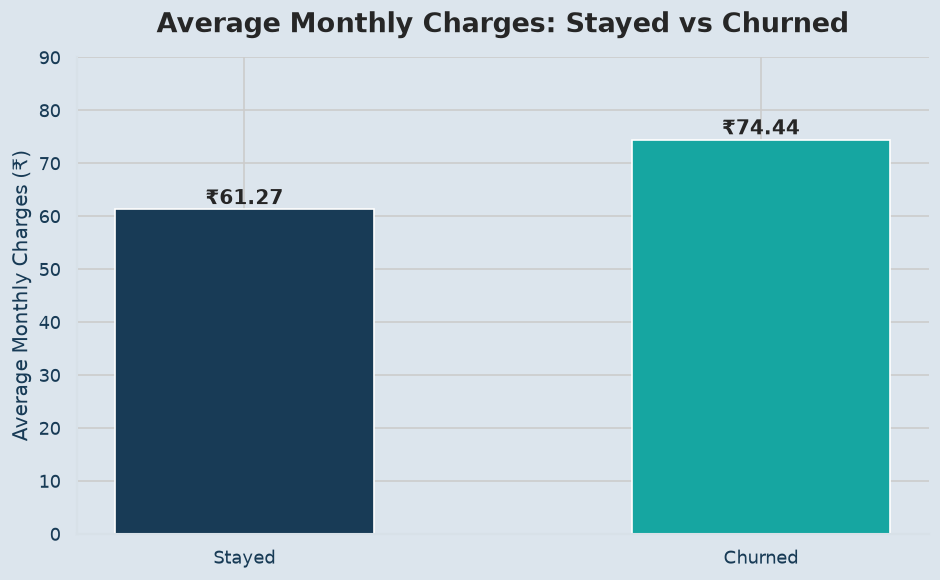

In [5]:
# Calculate average monthly charges by churn status
charges = df.groupby("Churn")["MonthlyCharges"].mean()

labels = ["Stayed", "Churned"]
values = [charges["No"], charges["Yes"]]

# Create the bar chart
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    labels,
    values,
    color=["#183B56", "#16A6A1"],
    width=0.5
)

# Display average charge values on the bars
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"₹{height:.2f}",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "Average Monthly Charges: Stayed vs Churned",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("Average Monthly Charges (₹)")
ax.set_ylim(0, 90)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Export the chart at 300 DPI
plt.savefig(
    "../Visualizations/03_average_monthly_charges.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=plt.gcf().get_facecolor()
)

# Display the chart
plt.show()

## 6. Average Customer Tenure by Churn Status

Compare the average customer tenure of customers who stayed with the company and those who churned. This visualisation helps identify whether customers with shorter relationships are more likely to leave.

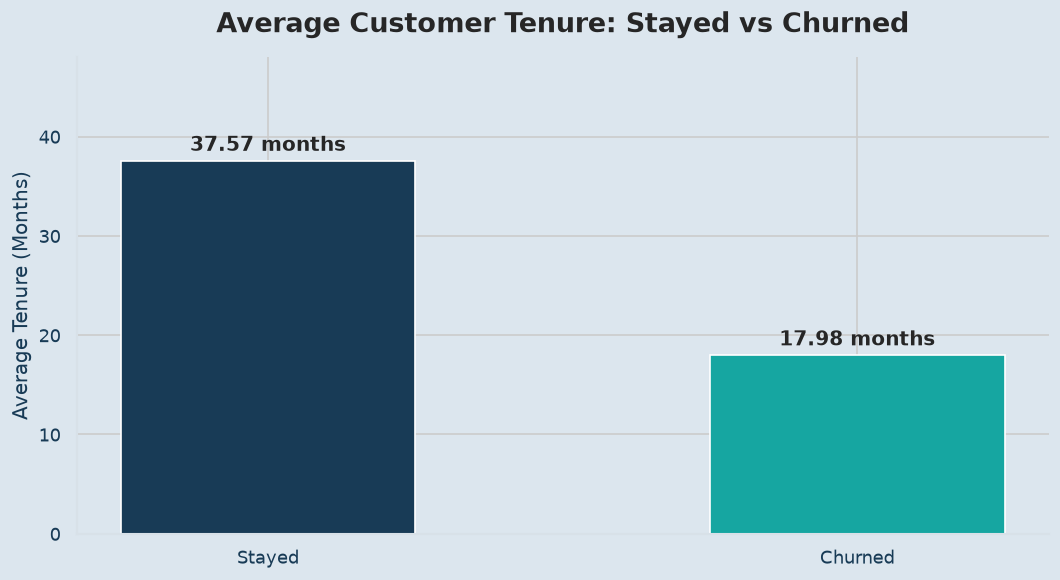

In [6]:
# Calculate average customer tenure by churn status
tenure_avg = df.groupby("Churn")["tenure"].mean()

labels = ["Stayed", "Churned"]
values = [tenure_avg["No"], tenure_avg["Yes"]]

# Create the bar chart
fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor("#DCE6EE")
ax.set_facecolor("#DCE6EE")

bars = ax.bar(
    labels,
    values,
    color=["#183B56", "#16A6A1"],
    width=0.5
)

# Display average tenure values on the bars
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f} months",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "Average Customer Tenure: Stayed vs Churned",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("Average Tenure (Months)")
ax.set_ylim(0, 48)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Export the chart at 300 DPI
plt.savefig(
    "../Visualizations/04_average_customer_tenure.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=plt.gcf().get_facecolor()
)

# Display the chart
plt.show()


## 7. Churn Rate by Contract and Internet Service

Analyse customer churn rates across different contract types and internet services. A heatmap helps identify high-risk customer segments and compare churn patterns across these combinations.

In [7]:
# Calculate churn rates by contract type and internet service
churn_heatmap = df.pivot_table(
    index="Contract",
    columns="InternetService",
    values="Churn",
    aggfunc=lambda x: (x == "Yes").mean() * 100
)

# Rename the internet service category for readability
churn_heatmap = churn_heatmap.rename(
    columns={"No": "No Internet Service"}
)

# Display the churn-rate table
print(churn_heatmap)
print(churn_heatmap.shape)

InternetService        DSL  Fiber optic  No Internet Service
Contract                                                    
Month-to-month   32.215863    54.605263            18.893130
One year          9.298246    19.294991             2.472527
Two year          1.910828     7.226107             0.783699
(3, 3)


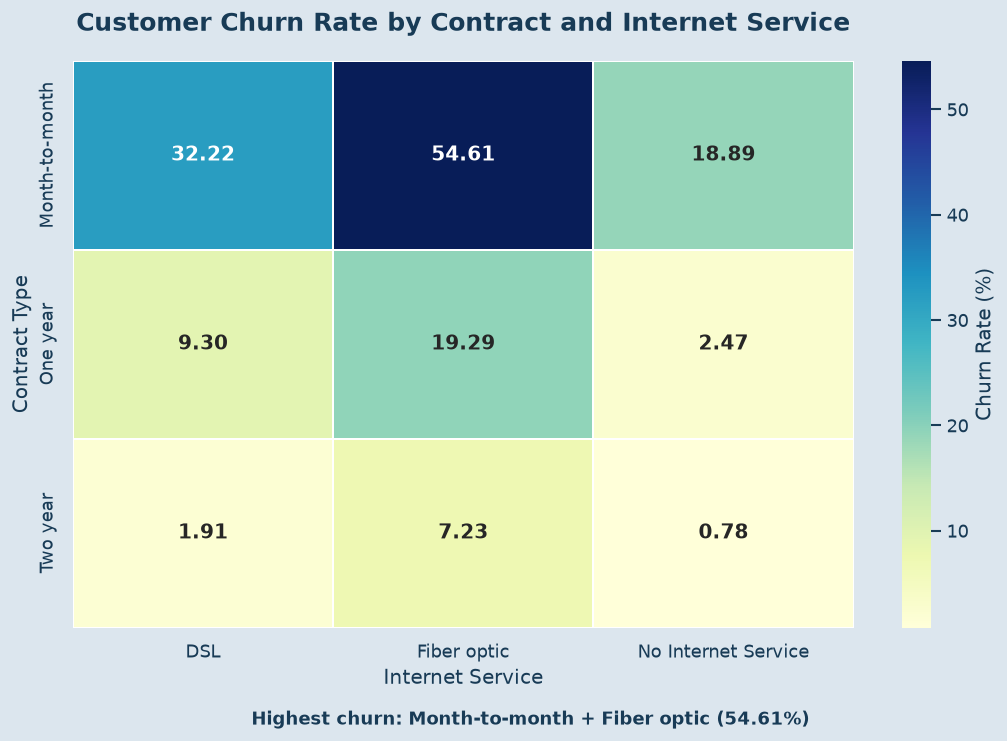

In [8]:
# Create the heatmap
fig, ax = plt.subplots(figsize=(9, 6))

fig.patch.set_facecolor("#DCE6EE")
ax.set_facecolor("#DCE6EE")

sns.heatmap(
    churn_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=1.2,
    linecolor="white",
    annot_kws={"fontsize": 12, "fontweight": "bold"},
    cbar_kws={"label": "Churn Rate (%)"},
    ax=ax
)

# Add chart title and axis labels
ax.set_title(
    "Customer Churn Rate by Contract and Internet Service",
    fontsize=15,
    fontweight="bold",
    color="#183B56",
    pad=18
)

ax.set_xlabel("Internet Service", fontsize=12)
ax.set_ylabel("Contract Type", fontsize=12)

# Highlight the highest churn segment
fig.text(
    0.5, -0.02,
    "Highest churn: Month-to-month + Fiber optic (54.61%)",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="#183B56"
)

plt.tight_layout()

# Export the heatmap at 300 DPI
plt.savefig(
    "../Visualizations/05_churn_contract_internet_heatmap.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=plt.gcf().get_facecolor()
)

# Display the heatmap
plt.show()

## 8. Churn Rate by Tenure Group

Analyse customer churn across three tenure groups: New (0–12 months), Medium (13–36 months), and Long-term (above 36 months). This visualisation helps identify how customer retention changes with the length of the customer relationship.

In [9]:
# Group customers based on their tenure
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 36, float("inf")],
    labels=["New", "Medium", "Long-term"]
)

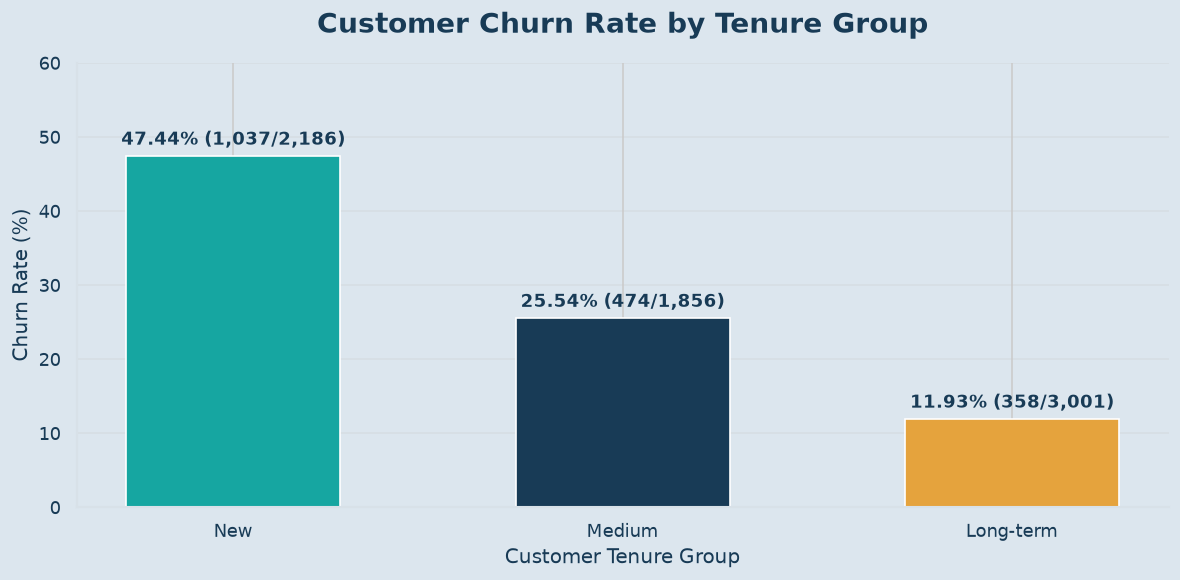

In [10]:
# Calculate churn rates for each tenure group
tenure_churn = (
    pd.crosstab(df["TenureGroup"], df["Churn"], normalize="index")["Yes"] * 100
)

tenure_churn = tenure_churn.reindex(["New", "Medium", "Long-term"])

# Calculate total and churned customers in each group
tenure_total = df["TenureGroup"].value_counts().reindex(tenure_churn.index)

tenure_counts = (
    df[df["Churn"] == "Yes"]["TenureGroup"]
    .value_counts()
    .reindex(tenure_churn.index)
)

# Create the bar chart
fig, ax = plt.subplots(figsize=(10, 5))

fig.patch.set_facecolor("#DCE6EE")
ax.set_facecolor("#DCE6EE")

bars = ax.bar(
    tenure_churn.index,
    tenure_churn.values,
    color=["#16A6A1", "#183B56", "#E5A33D"],
    width=0.55
)

# Display churn rates and customer counts
for i, bar in enumerate(bars):
    height = bar.get_height()
    group = tenure_churn.index[i]

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1.5,
        f"{height:.2f}% ({tenure_counts[group]:,}/{tenure_total[group]:,})",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color="#183B56"
    )

ax.set_title(
    "Customer Churn Rate by Tenure Group",
    fontsize=17,
    fontweight="bold",
    color="#183B56",
    pad=18
)

ax.set_xlabel("Customer Tenure Group", fontsize=12, color="#183B56")
ax.set_ylabel("Churn Rate (%)", fontsize=12, color="#183B56")

ax.set_ylim(0, 60)
ax.tick_params(axis="both", colors="#183B56", labelsize=11)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Export the chart at 300 DPI
plt.savefig(
    "../Visualizations/06_churn_by_tenure_group.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=plt.gcf().get_facecolor()
)

# Display the chart
plt.show()



In [11]:
import os

os.makedirs("../Visualizations", exist_ok=True)